# 05. 제안 모델 — KLUE-RoBERTa 멀티태스크 파인튜닝

**런타임: Colab GPU(T4)** — 메뉴 `런타임 → 런타임 유형 변경 → T4 GPU`. 전체 실행 약 10~15분.

| 항목 | 내용 |
|---|---|
| 사전학습 모델 | `klue/roberta-base` — 한국어 위키·뉴스·리뷰 등으로 사전학습된 RoBERTa (KLUE 벤치마크 공식 모델) |
| 구조 | 공유 인코더의 `[CLS]` 벡터 → **속성 헤드 8개**(각 4클래스) + **종합 평가 헤드 1개**(추천/비추천) |
| 학습 방식 | **파인튜닝(Fine-tuning)** — 인코더 전체 + 헤드를 함께 학습 |
| 손실 | 속성별 가중 교차엔트로피 평균 + λ × 종합 평가 교차엔트로피 (λ=0.5) |
| 클래스 불균형 | 속성마다 √(역빈도) 클래스 가중치 — "미언급" 쏠림 완화 |
| 종합 평가 데이터 | `voted_up`(작성자의 추천 버튼)을 정답으로 하는 정제 리뷰 10,677건 중 매 epoch 3,000건 무작위 추출 |
| 모델 선택 | 매 epoch Validation **속성 평균 Macro-F1**이 가장 높은 시점 저장, 3 epoch 개선 없으면 조기 종료 |

**왜 이 모델인가**
- 베이스라인(글자 n-gram)은 단어 표면만 보므로 "그래픽은 예쁜데 최적화가…"처럼 **한 문장 안에서 속성마다 감성이 갈리는** 문맥과, 반어·은어를 구분하지 못한다. 문맥을 양방향으로 읽는 Transformer 인코더가 이 한계를 보완한다.
- 한국어 전용 사전학습 모델이라 다국어 모델보다 토큰화 효율과 성능이 좋고, base 크기라 T4에서 수 분 내 학습된다.

**비교 실험(ablation):** 같은 설정에서 종합 평가 과제를 뺀 **속성 단독 모델**도 학습해, 멀티태스크가 속성 분류에 도움이 되는지 확인한다.

**산출물:** `models/absa_klue/`, `results/klue_*.{json,csv}`, `figures/05_*.png`

In [ ]:
# ── 환경 설정 ────────────────────────────────────────────
import os, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")       # Drive 연결 위치(수정 X)

# ▶ 프로젝트 폴더 경로 (01 노트북과 동일하게)
def find_root():
    """프로젝트 폴더 자동 탐색. Drive의 한글 폴더명이 NFD(자모 분리)로 저장되면
    "ML 기말" 같은 문자열 경로가 일치하지 않으므로, MyDrive를 직접 훑어
    data/processed/reviews_clean.csv가 있는 폴더를 찾는다(검수 파일이 있는 쪽 우선)."""
    if os.environ.get("ML_ROOT"):
        return Path(os.environ["ML_ROOT"])
    base = Path("/content/drive/MyDrive")
    cands = [p for p in [base, *base.glob("*"), *base.glob("*/*")]
             if p.is_dir() and (p / "data" / "processed" / "reviews_clean.csv").exists()]
    if not cands:
        print("⚠ 프로젝트 폴더를 찾지 못해 기본 경로를 사용합니다.")
        return base / "ML 기말"
    cands.sort(key=lambda p: not (p / "data" / "labeling" / "test_verify.csv").exists())
    if len(cands) > 1:
        print("⚠ 프로젝트 폴더 후보가 여러 개입니다 → 첫 번째 사용:", *cands, sep="\n   ")
    return cands[0]

ROOT = find_root()
sys.path.append(str(ROOT / "src"))      # src/preprocess.py 등 공용 모듈
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT, "| exists:", ROOT.exists())

Mounted at /content/drive
ROOT: /content/drive/MyDrive/머신러닝 포트폴리오 | exists: True


In [ ]:
import json, time, random, copy
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, get_linear_schedule_with_warmup
from sklearn.metrics import confusion_matrix, f1_score

from absa import (ASPECTS, ASPECTS_KO, LABELS, LABEL_NAMES, LABEL_NAMES_EN, OVERALL_NAMES,
                  load_splits, load_overall_splits, evaluate, summary, overall_metrics,
                  human_subset_report)
from absa_model import AbsaModel, predict_proba
from preprocess import clean_text

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| transformers", transformers.__version__, "| device", DEVICE,
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "⚠ GPU 없음 — 런타임 유형을 T4로 바꾸세요")

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

CFG = dict(model_name="klue/roberta-base", max_len=256, batch_size=32, epochs=8, patience=3,
           lr_encoder=3e-5, lr_head=1e-4, weight_decay=0.01, warmup_ratio=0.1,
           overall_lambda=0.5, overall_per_epoch=3000, dropout=0.1)
MODEL_DIR = ROOT / "models"; RES_DIR = ROOT / "results"
MODEL_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)
CFG

torch 2.14.1+cu130 | transformers 5.22.1 | device cuda | Tesla T4


{'model_name': 'klue/roberta-base',
 'max_len': 256,
 'batch_size': 32,
 'epochs': 8,
 'patience': 3,
 'lr_encoder': 3e-05,
 'lr_head': 0.0001,
 'weight_decay': 0.01,
 'warmup_ratio': 0.1,
 'overall_lambda': 0.5,
 'overall_per_epoch': 3000,
 'dropout': 0.1}

## 1. 데이터 — 04와 동일한 분할

- 속성: Train 1,500 / Val 200 / Test 300 (`src/absa.load_splits`, 테스트 라벨 = LLM 라벨)
- 종합 평가: Test·Val은 속성과 **같은 리뷰**, Train은 나머지 정제 리뷰 전체

In [ ]:
train, val, test, TEST_SOURCE = load_splits(ROOT)
o_tr, o_va, o_te = load_overall_splits(ROOT)

def overall_of(df):
    return df["voted_up"].astype(str).str.lower().eq("true").astype(int).values

# 속성 라벨이 있는 행 (종합 라벨도 함께 가짐)
asp_train = pd.DataFrame({"text": train["text"], "overall": overall_of(train)})
asp_train[ASPECTS] = train[ASPECTS].values
# 종합 라벨만 있는 행 (속성 Train 리뷰는 제외 — 중복 방지), 속성 라벨은 -100(무시)
ovr_only = o_tr[~o_tr["recommendationid"].isin(train["recommendationid"])][["text", "overall"]].reset_index(drop=True)
for a in ASPECTS:
    ovr_only[a] = -100

Y_va, Y_te = val[ASPECTS].values.astype(int), test[ASPECTS].values.astype(int)
O_va, O_te = overall_of(val), overall_of(test)
assert (O_te == o_te["overall"].values).all()
print(f"속성 Train {len(asp_train)} | 종합 전용 풀 {len(ovr_only):,} | Val {len(val)} | Test {len(test)}")

Train 1500 / Val 200 / Test 300  (테스트 라벨: LLM — 사람 검수는 참고용으로만 비교)
[종합 평가] Train 10,677 / Val 200 / Test 300 | 추천 비율 Train 0.832, Test 0.837
속성 Train 1500 | 종합 전용 풀 9,177 | Val 200 | Test 300


In [ ]:
# 클래스 가중치: 속성별 √(역빈도), 평균 1로 정규화
counts = np.stack([np.bincount(asp_train[a], minlength=4) for a in ASPECTS]) + 1      # (8, 4)
w = np.sqrt(counts.sum(1, keepdims=True) / (4 * counts))
ASPECT_W = torch.tensor(w / w.mean(1, keepdims=True), dtype=torch.float, device=DEVICE)
oc = np.bincount(o_tr["overall"], minlength=2) + 1
OVERALL_W = torch.tensor(np.sqrt(oc.sum() / (2 * oc)), dtype=torch.float, device=DEVICE)
pd.DataFrame(ASPECT_W.cpu().numpy(), index=ASPECTS_KO, columns=[LABEL_NAMES[c] for c in LABELS]).round(2)

,미언급,긍정,보통,부정
그래픽,0.28,0.59,1.69,1.44
최적화,0.28,0.98,1.78,0.96
스토리,0.31,0.56,1.62,1.51
게임성,0.72,0.62,1.35,1.31
조작감,0.31,1.32,1.42,0.95
사운드,0.15,0.45,1.91,1.50
가격,0.24,0.90,1.58,1.28
운영,0.33,1.32,1.61,0.73


## 2. 학습 함수

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(CFG["model_name"])

def batches(df, bs, shuffle, rng=None):
    idx = np.arange(len(df))
    if shuffle:
        rng.shuffle(idx)
    for i in range(0, len(idx), bs):
        b = df.iloc[idx[i:i + bs]]
        enc = tokenizer(b["text"].tolist(), padding=True, truncation=True,
                        max_length=CFG["max_len"], return_tensors="pt")
        yield (enc["input_ids"].to(DEVICE), enc["attention_mask"].to(DEVICE),
               torch.tensor(b[ASPECTS].values, dtype=torch.long, device=DEVICE),
               torch.tensor(b["overall"].values, dtype=torch.long, device=DEVICE))

def compute_loss(a_logits, o_logits, y_asp, y_ovr, lam):
    losses = []
    for j in range(len(ASPECTS)):
        m = y_asp[:, j] != -100
        if m.any():
            losses.append(F.cross_entropy(a_logits[m, j].float(), y_asp[m, j], weight=ASPECT_W[j]))
    l_asp = torch.stack(losses).mean() if losses else a_logits.sum() * 0
    l_ovr = F.cross_entropy(o_logits.float(), y_ovr, weight=OVERALL_W) if lam > 0 else o_logits.sum() * 0
    return l_asp + lam * l_ovr, l_asp.detach(), l_ovr.detach()

def predict_df(model, df):
    pa, po = predict_proba(model, tokenizer, df["text"].tolist(), max_len=CFG["max_len"],
                           batch_size=64, device=DEVICE)
    return pa.argmax(-1), po.argmax(-1), pa, po

def train_model(multitask: bool, tag: str):
    set_seed()
    lam = CFG["overall_lambda"] if multitask else 0.0
    model = AbsaModel.from_pretrained_encoder(CFG["model_name"], dropout=CFG["dropout"]).to(DEVICE)
    enc_params = [p for n, p in model.named_parameters() if n.startswith("encoder.")]
    head_params = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    opt = torch.optim.AdamW([{"params": enc_params, "lr": CFG["lr_encoder"]},
                             {"params": head_params, "lr": CFG["lr_head"]}], weight_decay=CFG["weight_decay"])
    n_rows = len(asp_train) + (CFG["overall_per_epoch"] if multitask else 0)
    steps = CFG["epochs"] * int(np.ceil(n_rows / CFG["batch_size"]))
    sched = get_linear_schedule_with_warmup(opt, int(CFG["warmup_ratio"] * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE == "cuda"))
    rng = np.random.RandomState(SEED)

    history, best_f1, best_state, bad = [], -1, None, 0
    for ep in range(1, CFG["epochs"] + 1):
        t0 = time.time(); model.train()
        epoch_df = asp_train
        if multitask:
            epoch_df = pd.concat([asp_train, ovr_only.sample(CFG["overall_per_epoch"], random_state=SEED + ep)],
                                 ignore_index=True)
        tot = [0.0, 0.0, 0.0]; nb_ = 0
        for ids, att, y_a, y_o in batches(epoch_df, CFG["batch_size"], True, rng):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
                a_logits, o_logits = model(ids, att)
            loss, la, lo = compute_loss(a_logits, o_logits, y_a, y_o, lam)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot[0] += loss.item(); tot[1] += la.item(); tot[2] += lo.item(); nb_ += 1

        pa, po, *_ = predict_df(model, val)
        vres = summary(evaluate(Y_va, pa))
        vo = overall_metrics(O_va, po)
        row = {"model": tag, "epoch": ep, "train_loss": tot[0] / nb_, "train_aspect_loss": tot[1] / nb_,
               "train_overall_loss": tot[2] / nb_, "val_macro_f1": vres["macro_f1"],
               "val_mention_f1": vres["mention_f1"], "val_overall_macro_f1": vo["overall_macro_f1"],
               "sec": time.time() - t0}
        history.append(row)
        improved = vres["macro_f1"] > best_f1
        if improved:
            best_f1, bad = vres["macro_f1"], 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        print(f"[{tag}] ep{ep} loss {row['train_loss']:.4f} (asp {row['train_aspect_loss']:.4f}, ovr {row['train_overall_loss']:.4f}) "
              f"| val Macro-F1 {row['val_macro_f1']:.4f} 언급F1 {row['val_mention_f1']:.4f} 종합F1 {row['val_overall_macro_f1']:.4f} "
              f"| {row['sec']:.0f}s {'★' if improved else ''}")
        if bad >= CFG["patience"]:
            print(f"[{tag}] 조기 종료 (epoch {ep})")
            break

    model.load_state_dict(best_state)
    print(f"[{tag}] best val Macro-F1 = {best_f1:.4f}")
    return model, pd.DataFrame(history)

config.json:   0%|          | 0.00/546 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/375 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/248k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/752k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

## 3. 학습 (학습 로그)

- ① **제안 모델:** 멀티태스크 (속성 + 종합 평가)
- ② **비교 실험:** 속성 단독 (λ=0, 종합 전용 데이터 미사용)

`RUN_ABLATION=False`로 두면 ②를 건너뛴다(시간 절약).

In [ ]:
RUN_ABLATION = True

model_mt, hist_mt = train_model(multitask=True, tag="KLUE-MT")
pred_mt = predict_df(model_mt, test)
model_mt.cpu()          # GPU 메모리 확보 (저장 시 다시 사용)
torch.cuda.empty_cache()

hist = [hist_mt]
if RUN_ABLATION:
    model_so, hist_so = train_model(multitask=False, tag="KLUE-aspect-only")
    pred_so = predict_df(model_so, test)
    del model_so; torch.cuda.empty_cache()
    hist.append(hist_so)

train_log = pd.concat(hist, ignore_index=True)
train_log.to_csv(RES_DIR / "klue_train_log.csv", index=False)
train_log.round(4)

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: klue/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_947/3311535653.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of th

[KLUE-MT] ep1 loss 1.2827 (asp 1.0377, ovr 0.4901) | val Macro-F1 0.3727 언급F1 0.4447 종합F1 0.8674 | 53s ★
[KLUE-MT] ep2 loss 0.8354 (asp 0.6780, ovr 0.3147) | val Macro-F1 0.5532 언급F1 0.7695 종합F1 0.8473 | 56s ★
[KLUE-MT] ep3 loss 0.6233 (asp 0.4977, ovr 0.2513) | val Macro-F1 0.6088 언급F1 0.8365 종합F1 0.8549 | 55s ★
[KLUE-MT] ep4 loss 0.4784 (asp 0.3816, ovr 0.1935) | val Macro-F1 0.6390 언급F1 0.7907 종합F1 0.8588 | 55s ★
[KLUE-MT] ep5 loss 0.3812 (asp 0.2975, ovr 0.1673) | val Macro-F1 0.6449 언급F1 0.8162 종합F1 0.8306 | 55s ★
[KLUE-MT] ep6 loss 0.3031 (asp 0.2321, ovr 0.1419) | val Macro-F1 0.6564 언급F1 0.8273 종합F1 0.8964 | 56s ★
[KLUE-MT] ep7 loss 0.2505 (asp 0.1898, ovr 0.1213) | val Macro-F1 0.6874 언급F1 0.8221 종합F1 0.8992 | 55s ★
[KLUE-MT] ep8 loss 0.2132 (asp 0.1665, ovr 0.0934) | val Macro-F1 0.6840 언급F1 0.8229 종합F1 0.8743 | 55s 
[KLUE-MT] best val Macro-F1 = 0.6874


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaModel LOAD REPORT from: klue/roberta-base
Key                       | Status     | 
--------------------------+------------+-
lm_head.layer_norm.weight | UNEXPECTED | 
lm_head.bias              | UNEXPECTED | 
lm_head.dense.weight      | UNEXPECTED | 
lm_head.dense.bias        | UNEXPECTED | 
lm_head.layer_norm.bias   | UNEXPECTED | 
pooler.dense.bias         | MISSING    | 
pooler.dense.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/tmp/ipykernel_947/3311535653.py:59: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of th

[KLUE-aspect-only] ep1 loss 1.1627 (asp 1.1627, ovr 0.0000) | val Macro-F1 0.3353 언급F1 0.3250 종합F1 0.4595 | 21s ★
[KLUE-aspect-only] ep2 loss 0.8092 (asp 0.8092, ovr 0.0000) | val Macro-F1 0.5004 언급F1 0.6982 종합F1 0.3730 | 21s ★
[KLUE-aspect-only] ep3 loss 0.5996 (asp 0.5996, ovr 0.0000) | val Macro-F1 0.5238 언급F1 0.7762 종합F1 0.4555 | 21s ★
[KLUE-aspect-only] ep4 loss 0.4715 (asp 0.4715, ovr 0.0000) | val Macro-F1 0.5648 언급F1 0.8024 종합F1 0.4254 | 21s ★
[KLUE-aspect-only] ep5 loss 0.3862 (asp 0.3862, ovr 0.0000) | val Macro-F1 0.6182 언급F1 0.8271 종합F1 0.4755 | 21s ★
[KLUE-aspect-only] ep6 loss 0.3233 (asp 0.3233, ovr 0.0000) | val Macro-F1 0.6597 언급F1 0.8438 종합F1 0.4314 | 21s ★
[KLUE-aspect-only] ep7 loss 0.2809 (asp 0.2809, ovr 0.0000) | val Macro-F1 0.6807 언급F1 0.8497 종합F1 0.4330 | 21s ★
[KLUE-aspect-only] ep8 loss 0.2549 (asp 0.2549, ovr 0.0000) | val Macro-F1 0.6796 언급F1 0.8403 종합F1 0.4267 | 21s 
[KLUE-aspect-only] best val Macro-F1 = 0.6807


,model,epoch,train_loss,train_aspect_loss,train_overall_loss,val_macro_f1,val_mention_f1,val_overall_macro_f1,sec
0,KLUE-MT,1,1.2827,1.0377,0.4901,0.3727,0.4447,0.8674,53.1204
1,KLUE-MT,2,0.8354,0.6780,0.3147,0.5532,0.7695,0.8473,55.5804
2,KLUE-MT,3,0.6233,0.4977,0.2513,0.6088,0.8365,0.8549,55.0873
3,KLUE-MT,4,0.4784,0.3816,0.1935,0.6390,0.7907,0.8588,55.0329
4,KLUE-MT,5,0.3812,0.2975,0.1673,0.6449,0.8162,0.8306,54.5201
5,KLUE-MT,6,0.3031,0.2321,0.1419,0.6564,0.8273,0.8964,56.1139
6,KLUE-MT,7,0.2505,0.1898,0.1213,0.6874,0.8221,0.8992,54.7479
7,KLUE-MT,8,0.2132,0.1665,0.0934,0.6840,0.8229,0.8743,54.7173
8,KLUE-aspect-only,1,1.1627,1.1627,0.0000,0.3353,0.3250,0.4595,21.0603
9,KLUE-aspect-only,2,0.8092,0.8092,0.0000,0.5004,0.6982,0.3730,21.1178


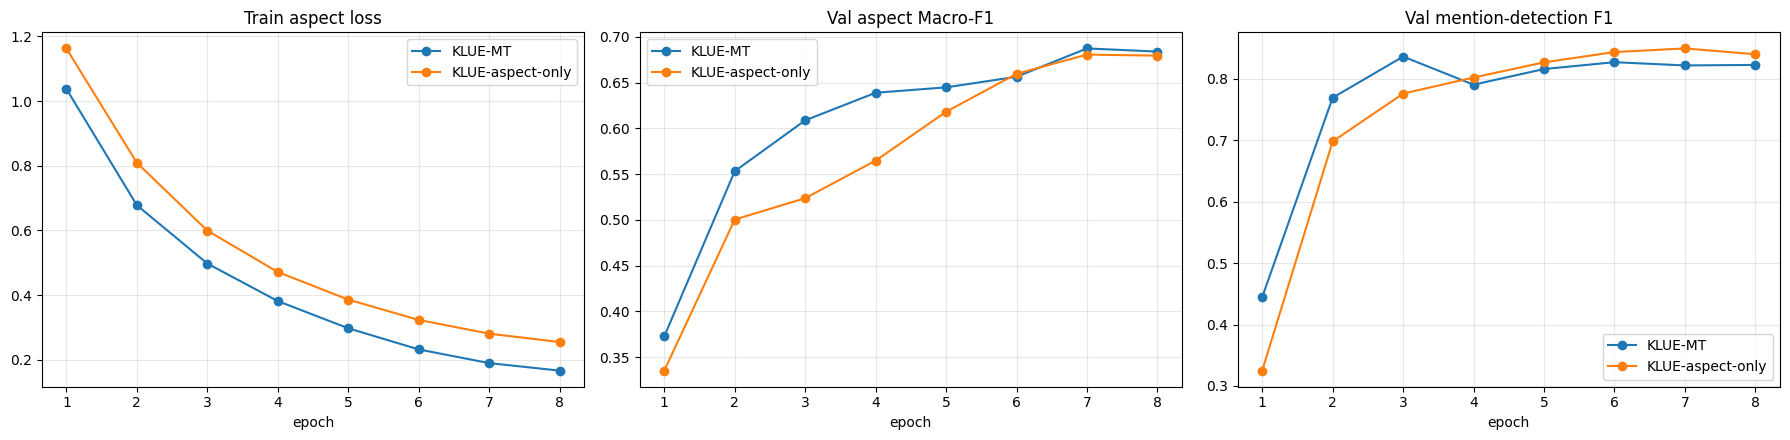

In [ ]:
# 학습곡선
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for tag, d in train_log.groupby("model", sort=False):
    axes[0].plot(d["epoch"], d["train_aspect_loss"], "o-", label=tag)
    axes[1].plot(d["epoch"], d["val_macro_f1"], "o-", label=tag)
    axes[2].plot(d["epoch"], d["val_mention_f1"], "o-", label=tag)
for ax, t in zip(axes, ["Train aspect loss", "Val aspect Macro-F1", "Val mention-detection F1"]):
    ax.set_title(t); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "05_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. 테스트셋 평가 및 모델 비교

베이스라인 점수는 04가 저장한 `results/baseline_metrics.json`에서 불러온다. 두 노트북 모두 같은 LLM 테스트 라벨로 채점한다.

In [ ]:
base = json.loads((RES_DIR / "baseline_metrics.json").read_text())
if base["test_label_source"] != TEST_SOURCE:
    print(f"⚠ 테스트 라벨 출처가 다릅니다 (04: {base['test_label_source']}, 05: {TEST_SOURCE}) → 04를 다시 실행하세요.")

res_mt = evaluate(Y_te, pred_mt[0])
rows = [{"모델": "Baseline: TF-IDF + LR", "학습 방식": "Scratch",
         "Macro-F1": base["macro_f1"], "Accuracy": base["accuracy"], "언급 감지 F1": base["mention_f1"],
         "종합 Macro-F1": base["overall_macro_f1"], "종합 Accuracy": base["overall_accuracy"]}]
if RUN_ABLATION:
    res_so = evaluate(Y_te, pred_so[0])
    s = summary(res_so)
    rows.append({"모델": "KLUE-RoBERTa (속성 단독)", "학습 방식": "Fine-tuning",
                 "Macro-F1": s["macro_f1"], "Accuracy": s["accuracy"], "언급 감지 F1": s["mention_f1"],
                 "종합 Macro-F1": np.nan, "종합 Accuracy": np.nan})
s, o = summary(res_mt), overall_metrics(O_te, pred_mt[1])
rows.append({"모델": "KLUE-RoBERTa 멀티태스크 (제안)", "학습 방식": "Fine-tuning",
             "Macro-F1": s["macro_f1"], "Accuracy": s["accuracy"], "언급 감지 F1": s["mention_f1"],
             "종합 Macro-F1": o["overall_macro_f1"], "종합 Accuracy": o["overall_accuracy"]})
compare = pd.DataFrame(rows).set_index("모델")
compare.to_csv(RES_DIR / "model_comparison.csv", encoding="utf-8-sig")
print(f"테스트 라벨 출처: {'사람 검수' if TEST_SOURCE == 'human' else 'LLM'} | 주지표: 속성 평균 Macro-F1")
compare.round(4)

테스트 라벨 출처: LLM | 주지표: 속성 평균 Macro-F1


,학습 방식,Macro-F1,Accuracy,언급 감지 F1,종합 Macro-F1,종합 Accuracy
모델,,,,,,
Baseline: TF-IDF + LR,Scratch,0.4916,0.8904,0.5921,0.8293,0.9067
KLUE-RoBERTa (속성 단독),Fine-tuning,0.6408,0.9279,0.8340,NaN,NaN
KLUE-RoBERTa 멀티태스크 (제안),Fine-tuning,0.6232,0.9292,0.8247,0.8512,0.9167


In [ ]:
# [참고] 사람 검수 시도 라벨로 채점했을 때 (최종 평가는 위의 LLM 라벨 기준)
bp_ = pd.read_csv(RES_DIR / "baseline_test_pred.csv", dtype={"recommendationid": str})
preds_h = {"Baseline: TF-IDF + LR": bp_[[f"{a}_pred" for a in ASPECTS]].values}
if RUN_ABLATION:
    preds_h["KLUE-RoBERTa (속성 단독)"] = pred_so[0]
preds_h["KLUE-RoBERTa 멀티태스크 (제안)"] = pred_mt[0]
hs_table, hs_agree, N_HUMAN = human_subset_report(ROOT, test, preds_h)
if N_HUMAN:
    hs_table.to_csv(RES_DIR / "model_comparison_human_subset.csv", encoding="utf-8-sig")
    display(hs_table.round(4))

[참고] 검수 시도 300행 (기준이 일정하지 않아 최종 평가에는 미사용) | LLM-검수 칸 일치율 0.992 | 검수에서 라벨이 바뀐 리뷰 20건 (7%)


,macro_f1,accuracy,mention_f1
LLM 라벨 (검수 라벨 대비),0.9797,0.9917,0.9758
Baseline: TF-IDF + LR,0.4887,0.8883,0.6019
KLUE-RoBERTa (속성 단독),0.6251,0.9242,0.8147
KLUE-RoBERTa 멀티태스크 (제안),0.6069,0.9254,0.8053


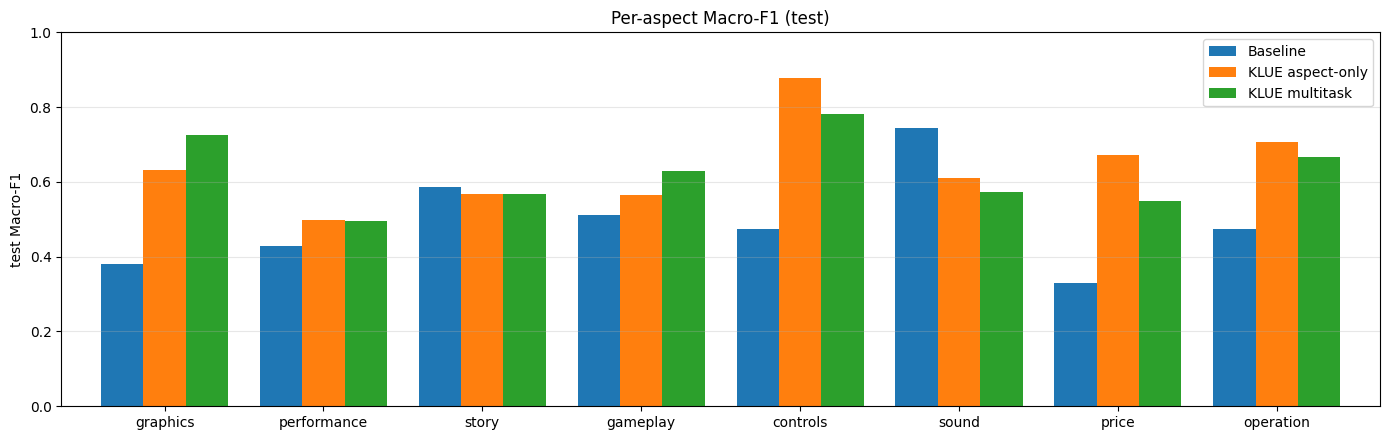

,속성,macro_f1,accuracy,mention_f1,n_mentioned
aspect,,,,,
graphics,그래픽,0.725,0.970,0.906,31
performance,최적화,0.494,0.963,0.800,15
story,스토리,0.566,0.930,0.838,52
gameplay,게임성,0.629,0.747,0.876,185
controls,조작감,0.781,0.973,0.812,17
sound,사운드,0.574,0.987,0.769,6
price,가격,0.550,0.957,0.800,22
operation,운영,0.666,0.907,0.796,51
MEAN,평균,0.623,0.929,0.825,379


In [ ]:
# 속성별 Macro-F1 비교
per = pd.DataFrame({"Baseline": pd.Series({a: base["per_aspect"][a]["macro_f1"] for a in ASPECTS})})
if RUN_ABLATION:
    per["KLUE aspect-only"] = res_so.loc[ASPECTS, "macro_f1"].astype(float)
per["KLUE multitask"] = res_mt.loc[ASPECTS, "macro_f1"].astype(float)

ax = per.plot.bar(figsize=(14, 4.5), width=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("test Macro-F1"); ax.grid(axis="y", alpha=0.3)
ax.set_title("Per-aspect Macro-F1 (test)"); ax.set_xticklabels(ASPECTS, rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_per_aspect_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
res_mt.round(3)

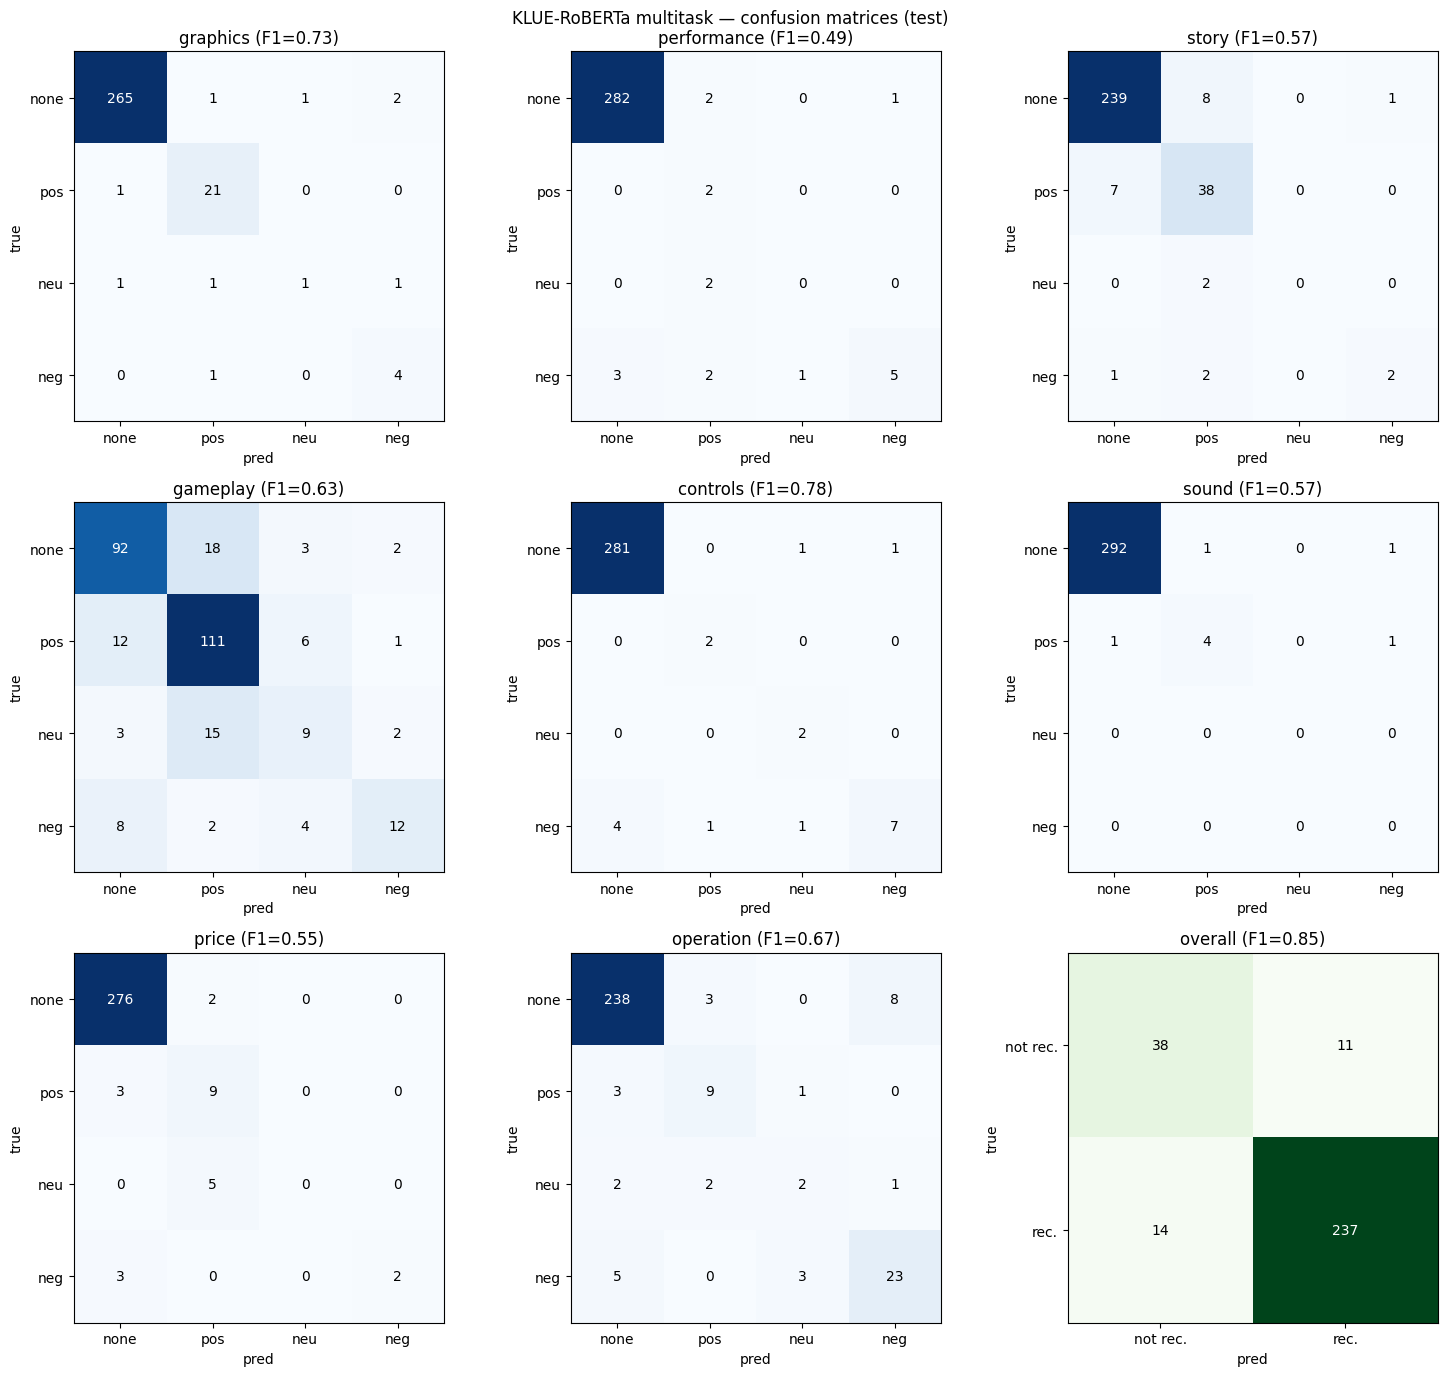

In [ ]:
# 제안 모델 혼동행렬 (행: 정답, 열: 예측) + 종합 평가
P_te = pred_mt[0]
fig, axes = plt.subplots(3, 3, figsize=(15, 14))
ticks = [LABEL_NAMES_EN[c] for c in LABELS]
for j, (ax, a) in enumerate(zip(axes.ravel(), ASPECTS)):
    cm = confusion_matrix(Y_te[:, j], P_te[:, j], labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for r in range(4):
        for c in range(4):
            ax.text(c, r, cm[r, c], ha="center", va="center", color="white" if cm[r, c] > cm.max() / 2 else "black")
    ax.set_xticks(range(4), ticks); ax.set_yticks(range(4), ticks)
    ax.set_title(f"{a} (F1={res_mt.loc[a, 'macro_f1']:.2f})"); ax.set_xlabel("pred"); ax.set_ylabel("true")
ax = axes.ravel()[-1]
cm = confusion_matrix(O_te, pred_mt[1], labels=[0, 1])
ax.imshow(cm, cmap="Greens")
for r in range(2):
    for c in range(2):
        ax.text(c, r, cm[r, c], ha="center", va="center", color="white" if cm[r, c] > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["not rec.", "rec."]); ax.set_yticks([0, 1], ["not rec.", "rec."])
ax.set_title(f"overall (F1={o['overall_macro_f1']:.2f})"); ax.set_xlabel("pred"); ax.set_ylabel("true")
fig.suptitle("KLUE-RoBERTa multitask — confusion matrices (test)")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. 오류 분석

- (a) 제안 모델이 **틀린** 사례 — 어떤 유형이 어려운가
- (b) 베이스라인은 틀리고 제안 모델은 **맞힌** 사례 — 문맥 이해의 효과

In [ ]:
bp = pd.read_csv(RES_DIR / "baseline_test_pred.csv", dtype={"recommendationid": str})
assert (bp["recommendationid"].values == test["recommendationid"].values).all()
B_te = bp[[f"{a}_pred" for a in ASPECTS]].values

def collect(mask):
    out = []
    for i, j in zip(*np.where(mask)):
        out.append({"idx": i, "속성": ASPECTS_KO[j], "정답": LABEL_NAMES[Y_te[i, j]],
                    "Baseline": LABEL_NAMES[B_te[i, j]], "KLUE": LABEL_NAMES[P_te[i, j]],
                    "text": test.loc[i, "text"][:150]})
    return pd.DataFrame(out)

pd.set_option("display.max_colwidth", 150)
wrong = collect(P_te != Y_te)
fixed = collect((B_te != Y_te) & (P_te == Y_te))
print(f"(a) KLUE 오답 {len(wrong)}칸 | (b) Baseline 오답 → KLUE 정답 {len(fixed)}칸 | 반대(KLUE만 오답) {((B_te == Y_te) & (P_te != Y_te)).sum()}칸")
print("\n(a) 오답 방향 (행: 정답, 열: KLUE 예측)")
print(pd.crosstab(wrong["정답"], wrong["KLUE"]))
wrong.sample(min(10, len(wrong)), random_state=SEED)

(a) KLUE 오답 170칸 | (b) Baseline 오답 → KLUE 정답 156칸 | 반대(KLUE만 오답) 63칸

(a) 오답 방향 (행: 정답, 열: KLUE 예측)
KLUE  긍정  미언급  보통  부정
정답                   
긍정     0   27   7   2
미언급   35    0   5  16
보통    27    6   0   4
부정     8   24   9   0


,idx,속성,정답,Baseline,KLUE,text
139,240,최적화,미언급,미언급,부정,개씹쓰레기 게임 검은 화면에서 로딩조차 안 넘어가고 인터넷에 나온 모든 해결책을 다 동원했지만 해결되지 않는 버그 좆망겜
30,64,운영,미언급,부정,부정,아 옛날 유아이 돌려내라 크래프톤 쓰레기들아 이상한 유아이 쳐 넣지마라
119,203,그래픽,미언급,미언급,긍정,퀄리티가 너무 좋아요! 완전 추천
29,64,조작감,부정,미언급,미언급,아 옛날 유아이 돌려내라 크래프톤 쓰레기들아 이상한 유아이 쳐 넣지마라
144,246,게임성,미언급,미언급,긍정,생각지도 못한 진한 짜장면 맛 그 맛이 참 중독일세
163,294,그래픽,미언급,긍정,부정,재미가 있긴합니다. 팰들을 포획해서 노예로 만들고 모험을 떠나는 건 정말 즐거운 일이죠. 다만 생존 게임의 건축 매니아 유저로써 불만이 많습니다. 1. 최적화 : 그래픽에 비해 최적화가 안좋은 것 같습니다. 2. 좁은 거점 범위 : 거점의 넓이가 너무 좁아요. ...
166,298,게임성,긍정,긍정,보통,소울라이크라고는 피구라밖에 안해본 똥손뉴비 깨는거 너무 힘들었다.. 용병으로 지인불러서 했는데 없었으면 아마 영원히 못깼을듯.. 실제로도 출시하자마자 2시간 안에 환불했다가 지인이 도와준대서 다시 함.. 2회차는 엄두가 안남 하지만 재밌었고 1회차 마지막에 즈음...
51,92,게임성,긍정,부정,미언급,"700시간 다되가는데 아직 3막도 못가봄 맵 구석에 쳐박힌 나무통, 바구니 하나하나 다 뜯어보고 대사별로 반응이 어떻게 다른지 저장-불러오기를 반복하는 내 성격상 언제 끝을 볼 수 있을지 모르겠음"
105,188,가격,긍정,미언급,미언급,120시간해도 초보인 이 게임 너무 너무 재미있고 시간 순삭됩니다;; 그동안 구매한 겜 중에 후회1도 안 나는 겜이 이게 처음;; 만약 힐링 좋아하신데 rpg까지 좋아하신다? 전혀 후회 안 해요!!
60,110,게임성,보통,보통,긍정,할게 없어요. 하지만 하면 할수록 뇌빼고 하기 좋은 듯.


In [ ]:
fixed.sample(min(10, len(fixed)), random_state=SEED)

,idx,속성,정답,Baseline,KLUE,text
96,206,조작감,부정,미언급,부정,세일해서 사서 하고 있는데 상당히 재미있다. 근데 타격감은 좀 별로다.
69,161,게임성,긍정,보통,긍정,고인물 게임이긴 한데 ㅈㄴ 재밌어요 걍 하세요 선택권 없어요 시발련드ㅜㄹ앚w
82,178,게임성,긍정,부정,긍정,"갓겜이라 칭찬이 자자해서 샀는데, 3D 멀미도 심하고 총게임도 더럽게 못하는 탓에 1챕터 눈 산에서 계속 미션 실패하면서 2~3시간을 보냈다. 그땐 너무 재미없고 멀미로 힘들기만해서 이런게 갓겜인가 싶었는데 진행할수록 아서란 캐릭터에 빠져들게 되고 2D처럼 캐릭..."
76,169,가격,긍정,미언급,긍정,짤막하게 잘함 옛날엔 구렸다는데 패치가 된건지 큰 불편함 없이 함 반값 할인 받아서 큰 불만 없이 재밌게 한 듯
114,231,게임성,긍정,미언급,긍정,300시간을 퍼먹은 3만원 게임. 사람에 따라 컨텐츠가 마르지 않는 게임. 이게 3만원이라고?? 얼엑이라고??
29,78,최적화,긍정,미언급,긍정,"운영 마인드 고트 게임제작사의 (PUBG 아시아스타즈 베트남방플사건으로 배그접고 위쳐 리마스터로 4회차 스피드런이나 빡쳐서합니다.)운영에 감탄합니다. 개재밌습니다. 새롭게 바뀐 그래픽, 편의설정, 빛깔, 카메라, 새로운 액션 등등 DLSS 가동안되는 똥컴인데도 ..."
94,200,게임성,긍정,미언급,긍정,"최적화 개판, 엉성한 적군 AI, 어디서 본 듯한 디자인과 구성. 자잘한 버그들 그러나, 이러한 수많은 단점들을 짓누르는 압도적인 순수 재미 게임은 재미가 최우선이라는 것을 깨닫게 해준 작품"
132,270,스토리,긍정,미언급,긍정,설치 후 처음 실행 버튼을 눌렀던 때로 돌아가고 싶다.. 타인의 인생과 죽음을 겪어본 것 마냥 첫 회차의 애달프고 격정적인 그 느낌을 잊을 수가 없어 다회차 정주행을 해도 이젠 그때 느낌을 받지 못하기에 싱글플레이는 그만둔지 오래됐네요 온라인에 애정하는 아서 모...
93,198,운영,미언급,부정,미언급,"내 컴퓨터 사고 나서 제일 처음으로 한 게임이자, 끝내기 싫어서 자꾸만 삭제하고 그리워하는 게임"
139,279,그래픽,부정,미언급,부정,"포켓몬 비주얼의 아크 서바이벌. 포획 시스템과 저작권으로 인해 팰들의 진화가 막히는 등 찐빠가 많다. 현실적인 자연배경과 서브컬처 느낌의 팰과 npc등 조합이 게임의 대한 몰입도를 떨어뜨리며 처음에는 신선해서 재밌었지만 게임을 계속할수록 어디에서 본 시스템, 다..."


## 6. 최종 모델 선택 및 저장

테스트 **속성 평균 Macro-F1**(주지표)이 가장 높은 모델을 최종 모델로 한다. 종합 평가 헤드를 가진 멀티태스크 모델이 서비스에 쓰이며, 속성 단독 모델이 더 높게 나오면 그 결과를 README에 그대로 기록한다.

In [ ]:
best_name = compare["Macro-F1"].idxmax()
print("주지표 최고 모델:", best_name)
print("서비스 탑재 모델: KLUE-RoBERTa 멀티태스크 (종합 평가 헤드 필요)")

SAVE_DIR = MODEL_DIR / "absa_klue"
meta = {"aspects": ASPECTS, "aspects_ko": ASPECTS_KO, "n_classes": 4,
        "label_names": LABEL_NAMES, "overall_names": OVERALL_NAMES,
        "max_len": CFG["max_len"], "base_model": CFG["model_name"], "cfg": CFG,
        "test_label_source": TEST_SOURCE, "test_metrics": {**summary(res_mt), **o}}
model_mt.save(SAVE_DIR, tokenizer, meta)

klue_metrics = {"model": "KLUE-RoBERTa multitask", **summary(res_mt), **o, "test_label_source": TEST_SOURCE,
                "per_aspect": res_mt.drop(index="MEAN")[["macro_f1", "accuracy", "mention_f1"]].astype(float).round(4).to_dict("index")}
if RUN_ABLATION:
    klue_metrics["ablation_aspect_only"] = summary(res_so)
if N_HUMAN:
    klue_metrics["human_subset_n"] = N_HUMAN
    klue_metrics["human_subset"] = hs_table.round(4).to_dict("index")
(RES_DIR / "klue_metrics.json").write_text(json.dumps(klue_metrics, ensure_ascii=False, indent=2))

pred = test[["recommendationid", "game", "text"]].copy()
for j, a in enumerate(ASPECTS):
    pred[f"{a}_true"], pred[f"{a}_pred"] = Y_te[:, j], P_te[:, j]
pred["overall_true"], pred["overall_pred"] = O_te, pred_mt[1]
pred["overall_p_rec"] = pred_mt[3][:, 1].round(4)
pred.to_csv(RES_DIR / "klue_test_pred.csv", index=False, encoding="utf-8-sig")

size = sum(p.stat().st_size for p in SAVE_DIR.iterdir()) / 1e6
print(f"저장: {SAVE_DIR} ({size:.0f} MB) — 100MB 초과이므로 GitHub 대신 HF Hub에 업로드")

주지표 최고 모델: KLUE-RoBERTa (속성 단독)
서비스 탑재 모델: KLUE-RoBERTa 멀티태스크 (종합 평가 헤드 필요)
저장: /content/drive/MyDrive/머신러닝 포트폴리오/models/absa_klue (222 MB) — 100MB 초과이므로 GitHub 대신 HF Hub에 업로드


In [ ]:
# 저장한 파일만으로 다시 불러와 추론 — app.py와 같은 방식 (사전학습 가중치 재다운로드 없음)
del model_mt; torch.cuda.empty_cache()
m, tok, mt = AbsaModel.load(SAVE_DIR, device=DEVICE)

samples = ["그래픽은 정말 예쁜데 최적화가 엉망이라 프레임이 계속 떨어져요",
           "스토리랑 OST가 미쳤다. 가격도 할인하면 혜자",
           "서버 터지고 핵쟁이 천지. 운영 좀 제대로 해라",
           "소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요.."]
pa, po = predict_proba(m, tok, [clean_text(s) for s in samples], max_len=mt["max_len"], device=DEVICE)
for s, a, p in zip(samples, pa.argmax(-1), po[:, 1]):
    asp = {ko: LABEL_NAMES[int(v)] for ko, v in zip(ASPECTS_KO, a) if v != 0}
    print(s); print(f"  → 종합: 추천 {p:.0%} | 속성: {asp or '언급 없음'}")

그래픽은 정말 예쁜데 최적화가 엉망이라 프레임이 계속 떨어져요
  → 종합: 추천 47% | 속성: {'그래픽': '긍정', '최적화': '부정'}
스토리랑 OST가 미쳤다. 가격도 할인하면 혜자
  → 종합: 추천 99% | 속성: {'스토리': '긍정', '사운드': '긍정', '가격': '긍정'}
서버 터지고 핵쟁이 천지. 운영 좀 제대로 해라
  → 종합: 추천 3% | 속성: {'운영': '부정'}
소매치기만 하고 다니다 보니, 현실에서도 하고 싶어요..
  → 종합: 추천 100% | 속성: 언급 없음


## 정리

- 모델 비교표(`results/model_comparison.csv`), 학습곡선·혼동행렬·속성별 비교 그래프는 README `## 4. 모델`, `## 5. 평가 결과`에 사용한다.